In [1]:
from pathlib import Path

import neuroglancer
import numpy as np
import tifffile

# Each TIFF page is a 2D (y, x) mask; page order forms the z axis.
dendrites_dir = Path.home() / "Library/Mobile Documents/com~apple~CloudDocs/dendrites"
dendrites_path = dendrites_dir / "DeepD3_Benchmark_dendrites.tif"
spines_path = dendrites_dir / "DeepD3_Benchmark_spines.tif"

def load_tiff_stack(path):
    with tifffile.TiffFile(path) as tif:
        return np.stack([page.asarray() for page in tif.pages])

dendrites_gray_zyx = load_tiff_stack(dendrites_path)
spines_gray_zyx = load_tiff_stack(spines_path)
if dendrites_gray_zyx.shape != spines_gray_zyx.shape:
    raise ValueError(
        f"Mask shapes differ: dendrites={dendrites_gray_zyx.shape}, "
        f"spines={spines_gray_zyx.shape}"
    )

# Foreground is bright; thresholding removes low-valued background/noise.
foreground_threshold = 127
dendrites_labels_zyx = (dendrites_gray_zyx > foreground_threshold).astype(np.uint32)
spines_labels_zyx = (spines_gray_zyx > foreground_threshold).astype(np.uint32)
print(
    "shape (z, y, x):", dendrites_labels_zyx.shape,
    "dendrite voxels:", int(np.count_nonzero(dendrites_labels_zyx)),
    "spine voxels:", int(np.count_nonzero(spines_labels_zyx)),
)

# The TIFFs have no physical voxel-size metadata, so use unitless voxel coordinates.
dimensions = neuroglancer.CoordinateSpace(
    names=["z", "y", "x"],
    units=["", "", ""],
    scales=[1, 1, 1],
)
dendrites_volume = neuroglancer.LocalVolume(
    data=dendrites_labels_zyx,
    dimensions=dimensions,
    volume_type="segmentation",
)
spines_volume = neuroglancer.LocalVolume(
    data=spines_labels_zyx,
    dimensions=dimensions,
    volume_type="segmentation",
)

viewer = neuroglancer.Viewer()
with viewer.txn() as state:
    state.dimensions = dimensions
    state.layout = "4panel"
    state.layers["Dendrites"] = neuroglancer.SegmentationLayer(source=dendrites_volume)
    state.layers["Dendrites"].segments = [1]
    state.layers["Dendrites"].segment_colors = {1: "#20d9a0"}
    state.layers["Spines"] = neuroglancer.SegmentationLayer(source=spines_volume)
    state.layers["Spines"].segments = [1]
    state.layers["Spines"].segment_colors = {1: "#ff4fa3"}

viewer

shape (z, y, x): (71, 366, 1444) dendrite voxels: 130163 spine voxels: 102615


http://127.0.0.1:49590/v/c3bf207ff8c28f82fc793e433132264971e7451a/

In [ ]:
# Extract individual spine meshes from the TIFF mask and calculate SpineTool metrics.
# Set this True only when nonzero TIFF values are instance IDs, not grayscale intensities.
spines_are_instance_labels = False
minimum_component_voxels = 20
voxel_spacing_zyx = (1.0, 1.0, 1.0)
num_of_chords = 30000  # Use 3000 for a quicker test; 30000 matches the paper's setting.
num_of_bins = 100

from scipy import ndimage as ndi
from skimage.measure import marching_cubes

connectivity = ndi.generate_binary_structure(3, 3)
components = []

if spines_are_instance_labels:
    for instance_id in np.unique(spines_gray_zyx):
        if instance_id == 0:
            continue
        instance_components, component_count = ndi.label(
            spines_gray_zyx == instance_id,
            structure=connectivity,
        )
        for component_id, bounds in enumerate(ndi.find_objects(instance_components), start=1):
            if bounds is None:
                continue
            components.append((f"label_{int(instance_id)}_{component_id}",
                               instance_components[bounds] == component_id))
            
else:
    binary_spines = spines_gray_zyx > foreground_threshold
    component_labels, component_count = ndi.label(binary_spines, structure=connectivity)
    for component_id, bounds in enumerate(ndi.find_objects(component_labels), start=1):
        if bounds is None:
            continue
        components.append((f"spine_{component_id:04d}",
                           component_labels[bounds] == component_id))

mesh_output_dir = dendrites_dir / "DeepD3_Benchmark_spine_meshes"
mesh_output_dir.mkdir(parents=True, exist_ok=True)
off_mesh_paths = {}
skipped_components = []

for component_name, component_mask in components:
    if int(np.count_nonzero(component_mask)) < minimum_component_voxels:
        skipped_components.append(component_name)
        continue

    padded_mask = np.pad(component_mask.astype(np.uint8), 1)
    vertices_zyx, faces = marching_cubes(
        padded_mask,
        level=0.5,
        spacing=voxel_spacing_zyx,
    )[:2]
    if len(faces) <= 10:
        skipped_components.append(component_name)
        continue

    # The TIFF stack is z,y,x; OFF meshes and SpineTool metrics use x,y,z coordinates.
    vertices_xyz = vertices_zyx[:, ::-1] - np.asarray(voxel_spacing_zyx[::-1]) #what is this
    mesh_path = mesh_output_dir / f"{component_name}.off"
    with mesh_path.open("w") as mesh_file:
        mesh_file.write(f"OFF\n{len(vertices_xyz)} {len(faces)} 0\n")
        for vertex in vertices_xyz:
            mesh_file.write(f"{vertex[0]:.9g} {vertex[1]:.9g} {vertex[2]:.9g}\n")
        for face in faces:
            mesh_file.write(f"3 {face[0]} {face[1]} {face[2]}\n")
    off_mesh_paths[component_name] = mesh_path

if not off_mesh_paths:
    raise ValueError(
        "No usable spine components were meshed. Check the TIFF threshold, "
        "instance-label setting, and minimum_component_voxels."
    )

print(f"Created {len(off_mesh_paths)} spine meshes in: {mesh_output_dir}")

try:
    from CGAL.CGAL_Polyhedron_3 import Polyhedron_3
    from spine_metrics import SpineMetricDataset
except ModuleNotFoundError as error:
    if error.name != "CGAL":
        raise
    print(
        "SpineTool metrics were not calculated: this kernel lacks the CGAL bindings. "
        "Run this notebook with the repo's CGAL-enabled environment."
    )
else:
    spine_meshes = {
        component_name: Polyhedron_3(str(mesh_path))
        for component_name, mesh_path in off_mesh_paths.items()
    }
    metric_names = [
        "ChordDistribution", "OpenAngle", "CVD", "AverageDistance",
        "LengthVolumeRatio", "LengthAreaRatio", "JunctionArea", "Length",
        "Area", "Volume", "ConvexHullVolume", "ConvexHullRatio",
    ]
    metric_params = [{"num_of_chords": num_of_chords, "num_of_bins": num_of_bins}]
    metric_params.extend({} for _ in metric_names[1:])

    spine_metrics = SpineMetricDataset()
    spine_metrics.calculate_metrics(spine_meshes, metric_names, metric_params)
    metrics_path = dendrites_dir / "DeepD3_Benchmark_spines_metrics.csv"
    spine_metrics.save(str(metrics_path))
    print(f"Calculated metrics for {len(spine_meshes)} spine components.")
    print(f"Metrics saved to: {metrics_path}")

if skipped_components:
    print(f"Skipped {len(skipped_components)} small components: {skipped_components}")

Created 364 spine meshes in: /Users/nahara/Library/Mobile Documents/com~apple~CloudDocs/dendrites/DeepD3_Benchmark_spine_meshes


KeyboardInterrupt: 

In [ ]:
# Predict the class of one selected spine using the repository's labeled training set.
from pathlib import Path

import numpy as np
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVC
from CGAL.CGAL_Polyhedron_3 import Polyhedron_3
from spine_fitter import SpineGrouping
from spine_metrics import SpineMetricDataset, calculate_metrics

# Change these two values to select a spine and feature set.
spine_to_classify = "spine_0001"
feature_set = "Classic"  # Options: "Classic", "Chord", "Combined"
chords_for_single_spine = 3000  # Increase to 30000 to match training CLDH precision.

repo_dir = Path.cwd()
mesh_dir = dendrites_dir / "DeepD3_Benchmark_spine_meshes"
target_mesh_path = mesh_dir / f"{spine_to_classify}.off"
if not target_mesh_path.exists():
    raise FileNotFoundError(f"Spine mesh not found: {target_mesh_path}. Run cell 2 first.")

train_dir = repo_dir / "train example dataset"
labels_path = train_dir / "manual_classification" / "manual_classification_merged_reduced.json"
train_metrics_path = train_dir / "metrics.csv"
if not labels_path.exists() or not train_metrics_path.exists():
    raise FileNotFoundError(
        f"Could not find labeled training data under {train_dir}. "
        "Run this notebook with the SpineTool repository as the working directory."
    )

training_labels = SpineGrouping().load(str(labels_path))
training_metrics = SpineMetricDataset().load(str(train_metrics_path))

feature_names = {
    "Classic": [
        "OpenAngle", "CVD", "AverageDistance", "LengthVolumeRatio",
        "LengthAreaRatio", "JunctionArea", "Length", "Area", "Volume",
        "ConvexHullVolume", "ConvexHullRatio",
    ],
    "Chord": ["ChordDistribution"],
    "Combined": [
        "ChordDistribution", "OpenAngle", "CVD", "AverageDistance",
        "LengthVolumeRatio", "LengthAreaRatio", "JunctionArea", "Length",
        "Area", "Volume", "ConvexHullVolume", "ConvexHullRatio",
    ],
}
if feature_set not in feature_names:
    raise ValueError(f"feature_set must be one of {list(feature_names)}")

class_names = {"Thin", "Mushroom", "Stubby"}
training_names = [
    name for name in training_metrics.ordered_spine_names
    if name in training_labels.samples and training_labels.get_group(name) in class_names
]
training_target = [training_labels.get_group(name) for name in training_names]
training_features = training_metrics.get_spines_subset(training_names).get_metrics_subset(
    feature_names[feature_set]
)

selected_mesh = Polyhedron_3(str(target_mesh_path))
target_metric_names = feature_names[feature_set]
target_metric_params = [{} for _ in target_metric_names]
if "ChordDistribution" in target_metric_names:
    chord_index = target_metric_names.index("ChordDistribution") ## what is this
    target_metric_params[chord_index] = {
        "num_of_chords": chords_for_single_spine,
        "num_of_bins": 100,
    }
target_values = calculate_metrics(selected_mesh, target_metric_names, target_metric_params)
target_data = np.asarray(
    [value for metric in target_values for value in metric.value_as_list()],
    dtype=float,
).reshape(1, -1)

classifier = GridSearchCV(SVC(kernel="rbf"), {"C": [1, 10]}, cv=4)
classifier.fit(training_features.as_array(), training_target)
predicted_class = classifier.predict(target_data)[0]

print(f"Spine: {spine_to_classify}")
print(f"Feature set: {feature_set}")
print(f"Predicted class: {predicted_class}")
if feature_set in {"Chord", "Combined"}:
    print(
        f"CLDH used {chords_for_single_spine} sampled chords; "
        "use 30000 for the training-set sampling precision."
    )

Spine: spine_0001
Feature set: Classic
Predicted class: Stubby


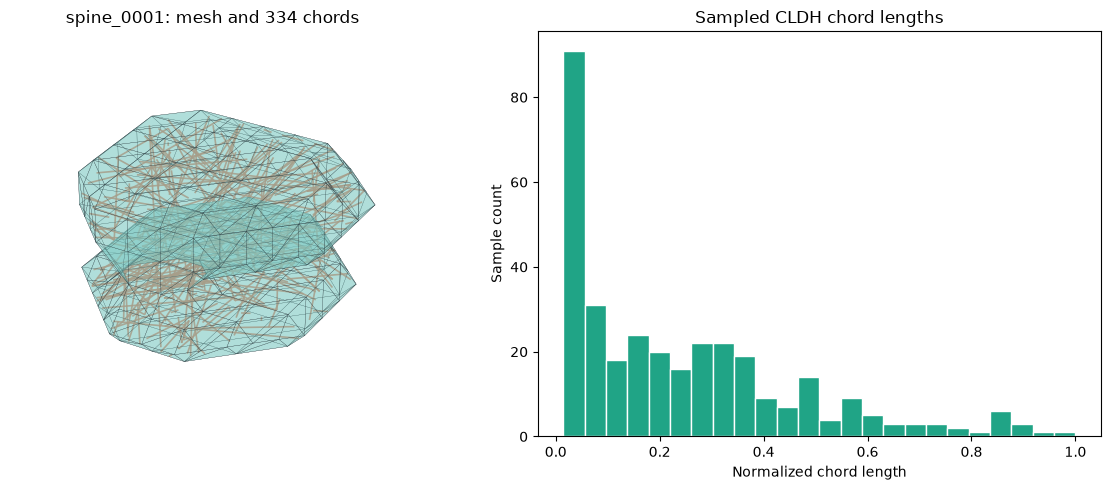

In [7]:
# Visualize a selected spine mesh with sampled CLDH chords.
from mpl_toolkits.mplot3d.art3d import Line3DCollection, Poly3DCollection
import matplotlib.pyplot as plt
from CGAL.CGAL_Polyhedron_3 import Polyhedron_3
from spine_metrics import ChordDistributionSpineMetric

spine_for_chord_view = spine_to_classify if "spine_to_classify" in globals() else "spine_0001"
chords_to_draw = 150  # Keep this modest for a clear, fast visualization.
chord_mesh_path = mesh_dir / f"{spine_for_chord_view}.off"
if not chord_mesh_path.exists():
    raise FileNotFoundError(f"Spine mesh not found: {chord_mesh_path}. Run cell 2 first.")

# Compute a small chord sample; this also provides the chord-length distribution.
chord_mesh = Polyhedron_3(str(chord_mesh_path))
chord_metric = ChordDistributionSpineMetric(
    chord_mesh,
    num_of_chords=chords_to_draw,
    num_of_bins=100,
)

# Read the OFF triangles for plotting the surface together with its sampled chords.
with chord_mesh_path.open() as off_file:
    off_tokens = [
        token
        for line in off_file
        for token in line.split("#", 1)[0].split()
    ]
if off_tokens[0] != "OFF":
    raise ValueError(f"Expected OFF mesh format: {chord_mesh_path}")
vertex_count, face_count, _ = map(int, off_tokens[1:4])
vertex_start = 4
face_start = vertex_start + vertex_count * 3
mesh_vertices = np.asarray(
    off_tokens[vertex_start:face_start], dtype=float
).reshape(-1, 3)
mesh_faces = []
token_index = face_start
for _ in range(face_count):
    vertices_in_face = int(off_tokens[token_index])
    face_indices = [
        int(value)
        for value in off_tokens[token_index + 1:token_index + 1 + vertices_in_face]
    ]
    if vertices_in_face == 3:
        mesh_faces.append(face_indices)
    token_index += vertices_in_face + 1

chord_segments = [
    [
        [point.x(), point.y(), point.z()]
        for point in chord
    ]
    for chord in chord_metric.chords
]

figure = plt.figure(figsize=(12, 5))
mesh_axis = figure.add_subplot(1, 2, 1, projection="3d")
mesh_surface = Poly3DCollection(
    mesh_vertices[np.asarray(mesh_faces)],
    facecolor="#80cbc4",
    edgecolor="#263238",
    linewidth=0.15,
    alpha=0.38,
)
mesh_axis.add_collection3d(mesh_surface)
mesh_axis.add_collection3d(Line3DCollection(
    chord_segments,
    colors="#e4572e",
    linewidths=1.2,
    alpha=0.85,
))
axis_limits = np.vstack([mesh_vertices.min(axis=0), mesh_vertices.max(axis=0)])
mesh_axis.set_xlim(axis_limits[:, 0])
mesh_axis.set_ylim(axis_limits[:, 1])
mesh_axis.set_zlim(axis_limits[:, 2])
mesh_axis.set_box_aspect(np.maximum(np.ptp(mesh_vertices, axis=0), 1e-6))
mesh_axis.set_title(f"{spine_for_chord_view}: mesh and {len(chord_segments)} chords")
mesh_axis.set_axis_off()

histogram_axis = figure.add_subplot(1, 2, 2)
histogram_axis.hist(chord_metric.chord_lengths, bins=24, color="#20a486", edgecolor="white")
histogram_axis.set_xlabel("Normalized chord length")
histogram_axis.set_ylabel("Sample count")
histogram_axis.set_title("Sampled CLDH chord lengths")
figure.tight_layout()
plt.show()

In [3]:
# Browse the component-colored spine volume and inspect per-spine scalar metrics.
import csv
from html import escape
from IPython.display import HTML, clear_output, display
import ipywidgets as widgets
import matplotlib.pyplot as plt
from scipy import ndimage as ndi

if globals().get("spines_are_instance_labels", False):
    spine_instance_labels_zyx = spines_gray_zyx.astype(np.uint32)
else:
    spine_instance_labels_zyx, _ = ndi.label(
        spines_gray_zyx > foreground_threshold,
        structure=ndi.generate_binary_structure(3, 3),
    )

spine_segment_ids = [
    int(segment_id)
    for segment_id in np.unique(spine_instance_labels_zyx)
    if segment_id != 0
]
spine_instances_volume = neuroglancer.LocalVolume(
    data=spine_instance_labels_zyx.astype(np.uint32),
    dimensions=dimensions,
    volume_type="segmentation",
)
spine_metrics_viewer = neuroglancer.Viewer()
with spine_metrics_viewer.txn() as state:
    state.dimensions = dimensions
    state.layout = "4panel"
    state.layers["Dendrites"] = neuroglancer.SegmentationLayer(source=dendrites_volume)
    state.layers["Dendrites"].segments = [1]
    state.layers["Spines"] = neuroglancer.SegmentationLayer(source=spine_instances_volume)
    state.layers["Spines"].segments = spine_segment_ids

spine_view_panel = widgets.VBox([
    widgets.HTML(
        value=(
            f'<p><a href="{escape(spine_metrics_viewer.get_viewer_url(), quote=True)}" '
            'target="_blank" rel="noopener">Open component-colored 3D spine view</a></p>'
            f"<p>{len(spine_segment_ids)} connected spine components shown.</p>"
        )
    )
])

metrics_csv_path = dendrites_dir / "DeepD3_Benchmark_spines_metrics.csv"
if metrics_csv_path.exists():
    with metrics_csv_path.open(newline="") as metrics_file:
        metric_rows = list(csv.DictReader(metrics_file))

    scalar_metric_names = []
    if metric_rows:
        for column_name in metric_rows[0]:
            if column_name == "Spine File":
                continue
            try:
                float(metric_rows[0][column_name])
            except (TypeError, ValueError):
                continue
            scalar_metric_names.append(column_name)

    if scalar_metric_names:
        metric_dropdown = widgets.Dropdown(
            options=scalar_metric_names,
            description="Metric:",
        )
        spine_dropdown = widgets.Dropdown(
            options=[row["Spine File"] for row in metric_rows],
            description="Spine:",
        )
        metric_output = widgets.Output()

        def render_metric_inspection(_=None):
            metric_name = metric_dropdown.value
            spine_name = spine_dropdown.value
            selected_row = next(
                row for row in metric_rows if row["Spine File"] == spine_name
            )
            values = [float(row[metric_name]) for row in metric_rows]
            with metric_output:
                clear_output(wait=True)
                display(HTML(
                    f"<strong>{escape(spine_name)}</strong>: "
                    f"{float(selected_row[metric_name]):.6g} {escape(metric_name)}"
                ))
                figure, axis = plt.subplots(figsize=(7, 3))
                axis.hist(values, bins=24, color="#20a486", edgecolor="white")
                axis.axvline(float(selected_row[metric_name]), color="#e76f51", linewidth=2)
                axis.set_xlabel(metric_name)
                axis.set_ylabel("Spine count")
                axis.set_title(f"{metric_name} distribution")
                figure.tight_layout()
                plt.show()

        metric_dropdown.observe(render_metric_inspection, names="value")
        spine_dropdown.observe(render_metric_inspection, names="value")
        metrics_panel = widgets.VBox([widgets.HBox([metric_dropdown, spine_dropdown]), metric_output])
        render_metric_inspection()
    else:
        metrics_panel = widgets.HTML("No scalar metric columns were found in the metrics CSV.")
else:
    metrics_panel = widgets.HTML(
        "Metrics CSV not found. Run the metrics cell first to populate this view."
    )

visualization_tabs = widgets.Tab(children=[spine_view_panel, metrics_panel])
visualization_tabs.set_title(0, "Spines")
visualization_tabs.set_title(1, "Metrics")
display(visualization_tabs)